# 03 · The signal and a first in-sample backtest

**The rules (version 1), fixed before looking at any results:**

| Piece | Rule |
|---|---|
| Rolling VWAP | 20 trading days, built from daily bars |
| Signal | today's distance below VWAP is **2σ or more**, where σ is the typical distance over the previous 60 days |
| Entry | buy at the **next day's open** after a signal |
| Exit | sell at the next open after the close gets back to VWAP, **or** after 10 trading days, whichever comes first |
| Positions | at most one open trade per stock |

**The data is split once, now:**

- **In-sample:** 24 Oct 2016 to 23 Oct 2023 (7 years). Everything in this notebook uses only this period.
- **Out-of-sample:** 24 Oct 2023 to 23 Oct 2026 (3 years). Untouched until the final test.

The strategy code lives in [`src/vwap_dip.py`](../src/vwap_dip.py), so every later notebook runs exactly the same rules.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from vwap_dip import END, SPLIT, START, Params, run

SYMBOLS = pd.read_csv(ROOT / "data" / "universe" / "universe_v1.csv")["yahoo_symbol"].tolist()

# chart colours
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"


def tidy(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#b9b8b2")
    ax.tick_params(colors=MUTED)


Params()

Params(vwap_days=20, sigma_days=60, entry_z=-2.0, max_days=10)

## Part A · A rolling VWAP from daily bars

The real VWAP averages every *trade* by its size, but daily bars don't contain individual trades. Each day's average trade price is approximated by its **typical price**, (high + low + close) / 3, weighted by that day's volume:

$$\text{VWAP}_t = \frac{\sum_{i=t-19}^{t} \text{typical}_i \times \text{volume}_i}{\sum_{i=t-19}^{t} \text{volume}_i}$$

**All prices are dividend-adjusted.** Suppose a stock pays a €0.50 dividend in the middle of the window. Its price drops by about €0.50 that morning, and unadjusted, today's price would sit below a VWAP still full of pre-dividend prices. That's a fake dip.

**From distance to signal:**

- `dist` = close / VWAP − 1, so −5% means the close is 5% below VWAP.
- `dist_sd` = how big that distance usually is, measured over the **previous** 60 days (the same `.shift(1)` as notebook 02).
- `z` = `dist` / `dist_sd`, today's distance in units of the usual distance. **Signal: z ≤ −2.**

Everything on a row is known at that day's close, and the order fills at the *next* open. So no number used for a decision comes from after the decision.

In [2]:
bars, all_trades = run(SYMBOLS)

# in-sample only, by entry date
trades = all_trades[(all_trades["entry_date"] >= START) & (all_trades["entry_date"] < SPLIT)].reset_index(drop=True)

bars["TUB.MC"].loc["2020-02-20":"2020-02-28", ["close", "vwap", "dist", "dist_sd", "z"]].round(4)

,close,vwap,dist,dist_sd,z
Date,,,,,
2020-02-20,2.2328,2.2746,-0.0184,0.0268,-0.6862
2020-02-21,2.1755,2.2681,-0.0408,0.0267,-1.5271
2020-02-24,2.0302,2.2485,-0.0971,0.0269,-3.6103
2020-02-25,1.9730,2.2317,-0.1159,0.0290,-3.9910
2020-02-26,1.8937,2.1808,-0.1317,0.0319,-4.1260
2020-02-27,1.9025,2.1555,-0.1174,0.0352,-3.3306
2020-02-28,1.9025,2.1339,-0.1084,0.0375,-2.8946


How often does the signal fire? More often than the 2.3% of days in notebook 02. A stock that falls well below its VWAP tends to *stay* below for several days, so signals come in runs. One position per stock means only the first day of a run opens a trade.

In [3]:
signal_share = pd.Series({s: 100 * (b.loc[START:SPLIT, "z"] <= -2).mean() for s, b in bars.items()}, name="% of in-sample days with z ≤ -2")
signal_share.round(1)

OHLA.MC    5.4
EDR.MC     5.4
AMP.MC     7.3
ORY.MC     7.8
TUB.MC     3.5
ENC.MC     3.2
NXT.MC     5.2
DOM.MC     4.9
GSJ.MC     6.0
ADX.MC     6.8
Name: % of in-sample days with z ≤ -2, dtype: float64

## Part B · What a few trades look like

Tubacex, early 2020. One trade bounces back to VWAP quickly. Then COVID arrives, and the strategy buys twice into a falling market (the falling knife) before the rebound pays out.

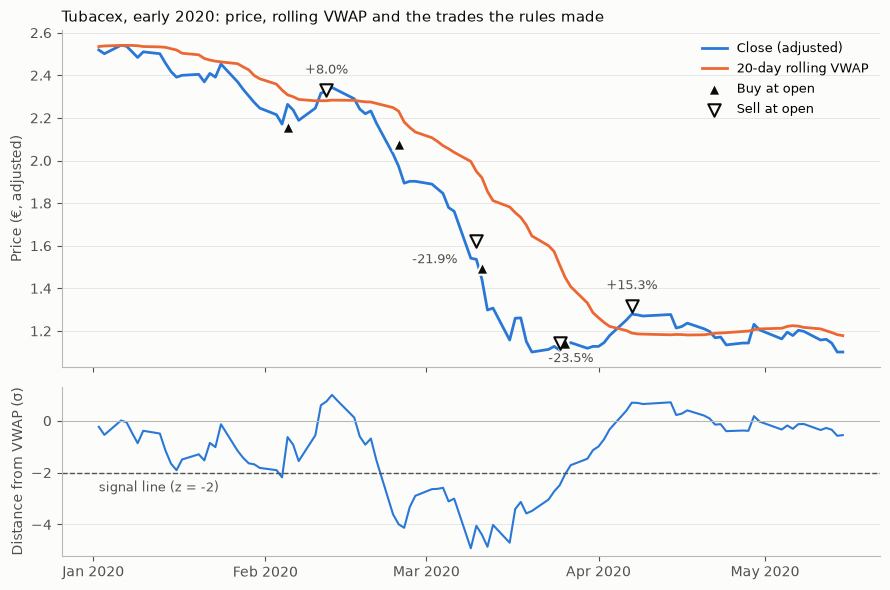

In [4]:
ex = bars["TUB.MC"].loc["2020-01-02":"2020-05-15"]
ex_trades = trades[(trades["symbol"] == "TUB.MC") & (trades["entry_date"].between("2020-01-02", "2020-05-15"))]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}, facecolor=SURFACE)
ax1.plot(ex.index, ex["close"], color=BLUE, linewidth=2, label="Close (adjusted)")
ax1.plot(ex.index, ex["vwap"], color=ORANGE, linewidth=2, label="20-day rolling VWAP")
ax1.scatter(ex_trades["entry_date"], ex_trades["entry_price"], marker="^", s=80, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Buy at open")
ax1.scatter(ex_trades["exit_date"], ex_trades["exit_price"], marker="v", s=80, color=SURFACE, edgecolor=INK, linewidth=1.5, zorder=3, label="Sell at open")
# label each sale with its return, nudged into empty space so it doesn't sit on a line
offsets = [(0, 12), (-30, -16), (8, -14), (0, 12)]
for (_, t), off in zip(ex_trades.iterrows(), offsets):
    ax1.annotate(f"{t['return']:+.1%}", (t["exit_date"], t["exit_price"]), textcoords="offset points",
                 xytext=off, ha="center", fontsize=9, color=MUTED)
ax1.set_ylabel("Price (€, adjusted)", color=MUTED)
ax1.set_title("Tubacex, early 2020: price, rolling VWAP and the trades the rules made", loc="left", fontsize=11, color=INK)
ax1.legend(frameon=False, loc="upper right", fontsize=9)

ax2.plot(ex.index, ex["z"], color=BLUE, linewidth=1.5)
ax2.axhline(-2, color=MUTED, linestyle="--", linewidth=1)
ax2.axhline(0, color="#b9b8b2", linewidth=0.8)
ax2.text(ex.index[0], -2.3, "signal line (z = -2)", fontsize=9, color=MUTED, va="top")
ax2.set_ylabel("Distance from VWAP (σ)", color=MUTED)
for ax in (ax1, ax2):
    tidy(ax)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

## Part C · The trade list

`simulate()` in `src/vwap_dip.py` walks through each stock day by day, the way a trader would live through it. At each close it asks one question: *flat?* then check for a signal; *in a trade?* then check the exits. Every order fills at the next open. A plain loop is easier to check for mistakes than a clever vectorised version, and with 2,600 days × 10 stocks it's still instant.

In [5]:
print(len(trades), "in-sample trades")
trades.head()

225 in-sample trades


,symbol,signal_date,entry_date,exit_date,signal_z,entry_price,exit_price,days_held,exit_reason,return
0,OHLA.MC,2016-11-17,2016-11-18,2016-12-02,-2.043522,2.367685,2.354358,10,time stop,-0.005629
1,ORY.MC,2017-02-17,2017-02-20,2017-03-06,-2.605761,3.810000,4.092000,10,back to VWAP,0.074016
2,EDR.MC,2017-03-13,2017-03-14,2017-03-28,-2.074832,3.180000,3.185000,10,time stop,0.001572
3,GSJ.MC,2017-03-31,2017-04-03,2017-04-19,-2.088594,3.135041,2.602676,10,time stop,-0.169811
4,NXT.MC,2017-04-03,2017-04-04,2017-04-20,-2.466353,1.156258,1.000608,10,time stop,-0.134615


## Part D · First results (in-sample, before costs)

In [6]:
r = trades["return"]
win = r > 0
summary = pd.Series({
    "trades": len(r),
    "win rate %": 100 * win.mean(),
    "average win %": 100 * r[win].mean(),
    "average loss %": 100 * r[~win].mean(),
    "EV per trade % (mean)": 100 * r.mean(),
    "median trade %": 100 * r.median(),
    "std of trade returns %": 100 * r.std(),
    "average days held": trades["days_held"].mean(),
})
summary.round(2)

trades                    225.00
win rate %                 52.00
average win %               7.43
average loss %             -8.64
EV per trade % (mean)      -0.29
median trade %              0.27
std of trade returns %     11.42
average days held           8.67
dtype: float64

This is the EV formula from the start of the project, applied to real numbers: EV = P(win) × average win + P(loss) × average loss. A win rate above 50% and a negative EV, the same situation as the 60%-win-rate example we worked through at the start.

In [7]:
p = win.mean()
print("P(win) x avg win + P(loss) x avg loss = %.3f%%" % (100 * (p * r[win].mean() + (1 - p) * r[~win].mean())))
print("mean of all trades                    = %.3f%%" % (100 * r.mean()))

P(win) x avg win + P(loss) x avg loss = -0.288%
mean of all trades                    = -0.288%


In [8]:
by_exit = trades.groupby("exit_reason")["return"].agg(trades="size", avg_return="mean")
by_exit["avg_return"] *= 100
by_exit.round(2)

,trades,avg_return
exit_reason,,
back to VWAP,87,8.87
time stop,138,-6.06


The two exits tell the whole story. Trades that get back to VWAP make a lot, because the price had to climb from 2σ below to the average. Trades that never get there hit the time stop and lose about as much. **The strategy is a bet on which group is bigger, and here they roughly cancel out.**

In [9]:
by_stock = trades.groupby("symbol")["return"].agg(trades="size", avg_return="mean", win_rate=lambda x: (x > 0).mean())
by_stock[["avg_return", "win_rate"]] *= 100
by_year = trades.groupby(trades["entry_date"].dt.year)["return"].agg(trades="size", avg_return="mean")
by_year["avg_return"] *= 100
display(by_stock.round(2), by_year.round(2))

,trades,avg_return,win_rate
symbol,,,
ADX.MC,22,-2.57,36.36
AMP.MC,24,-1.33,50.00
DOM.MC,22,0.80,63.64
EDR.MC,21,-4.03,47.62
ENC.MC,19,0.57,47.37
GSJ.MC,21,-1.94,42.86
NXT.MC,25,-0.13,56.00
OHLA.MC,22,-1.72,45.45
ORY.MC,31,3.75,58.06


,trades,avg_return
entry_date,,
2016,1,-0.56
2017,35,2.58
2018,40,-0.85
2019,25,1.63
2020,37,-3.56
2021,29,0.91
2022,30,-1.08
2023,28,-0.83


## Part E · Is it better than buying on random days?

A −0.29% average could be bad luck, and a +0.29% could have been good luck. To tell, we need to know how much an average of 225 trades wobbles *by chance*. We can measure that directly:

1. For every real trade, make a **random twin**: same stock, same number of days held, but entered on a random in-sample day.
2. Average the 225 twins. That's what a strategy with *no* information would have made this time.
3. Repeat 2,000 times. The spread of those averages is the chance wobble.

If the real strategy beats almost all the random runs, the signal is probably doing something. If it sits in the middle, we can't tell it apart from luck.

In [10]:
rng = np.random.default_rng(42)  # fixed seed so the result is reproducible
opens = {s: b["open"].to_numpy() for s, b in bars.items()}
entry_pool = {s: np.flatnonzero((b.index >= START) & (b.index < SPLIT)) for s, b in bars.items()}


def random_twins_average():
    rets = []
    for s, h in zip(trades["symbol"], trades["days_held"]):
        e = rng.choice(entry_pool[s])
        rets.append(opens[s][e + h] / opens[s][e] - 1)
    return np.mean(rets)


random_averages = np.array([random_twins_average() for _ in range(2000)])
share_better = (random_averages >= r.mean()).mean()
print("strategy average:        %.2f%%" % (100 * r.mean()))
print("random runs, middle 90%%: %.2f%% to %.2f%%" % (100 * np.percentile(random_averages, 5), 100 * np.percentile(random_averages, 95)))
print("random runs that did at least as well: %.0f%%" % (100 * share_better))

strategy average:        -0.29%
random runs, middle 90%: -0.62% to 1.46%
random runs that did at least as well: 85%


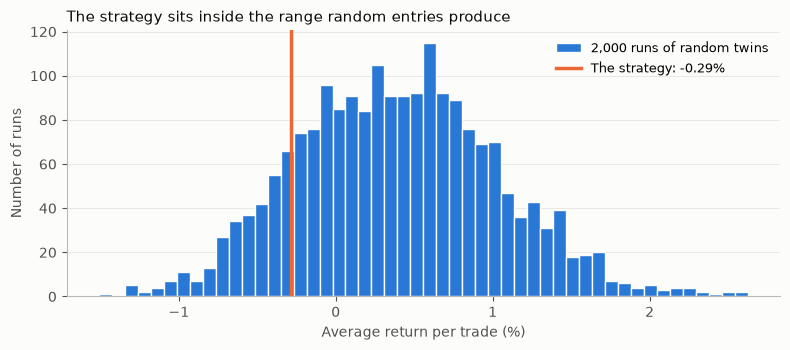

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=SURFACE)
ax.hist(100 * random_averages, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=1, label="2,000 runs of random twins")
ax.axvline(100 * r.mean(), color=ORANGE, linewidth=2.5, label=f"The strategy: {100 * r.mean():+.2f}%")
ax.set_xlabel("Average return per trade (%)", color=MUTED)
ax.set_ylabel("Number of runs", color=MUTED)
ax.set_title("The strategy sits inside the range random entries produce", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="upper right", fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()

One caveat makes this test too *generous*, not too harsh. Real signals cluster on crash days (notebook 02), so real trades rise and fall together, while random twins are spread out. Clustered trades wobble more as a group, so the true chance range is *wider* than the histogram shows. That makes it even harder to call the strategy's result anything but noise.

## Part F · The edge hypothesis: market-wide vs stock-specific dips

At the start we guessed *why* a dip might revert: a hurried seller (for example, everyone dumping stocks in a market-wide panic) should bounce back, while a better-informed seller (company-specific bad news) shouldn't. This test was planned before seeing any results, so running it once is fair.

Rough split: a dip is **market-wide** if 3 or more of our 10 stocks signalled on the same day, and **stock-specific** otherwise.

In [12]:
z_all = pd.DataFrame({s: b["z"] for s, b in bars.items()})
stocks_signalling = (z_all <= -2).sum(axis=1)
trades["kind"] = np.where(trades["signal_date"].map(stocks_signalling) >= 3, "market-wide", "stock-specific")

by_kind = trades.groupby("kind")["return"].agg(trades="size", avg_return="mean", median_return="median", win_rate=lambda x: (x > 0).mean())
by_kind[["avg_return", "median_return", "win_rate"]] *= 100
by_kind.round(2)

,trades,avg_return,median_return,win_rate
kind,,,,
market-wide,95,-0.82,0.77,54.74
stock-specific,130,0.10,-0.03,50.00


The averages point the *opposite* way from our guess: market-wide dips did worse, dragged down by the COVID crash. But each group has only about 100 trades swinging ±11%. Part E showed averages of that kind wobble by roughly a percentage point by chance, more for smaller groups. **So this test can't tell the two kinds apart.** That's a real finding: we have no evidence for the hypothesis in this data.

## Part G · Costs

Costs are subtracted from every trade, so they can only lower the EV. With a negative EV before costs, no cost level makes this version profitable. For reference, at a few round-trip cost levels (buy and sell together):

In [13]:
pd.Series({f"{c:.1f}% round trip": 100 * r.mean() - c for c in [0.0, 0.2, 0.4, 0.6]}, name="EV per trade %").round(2)

0.0% round trip   -0.29
0.2% round trip   -0.49
0.4% round trip   -0.69
0.6% round trip   -0.89
Name: EV per trade %, dtype: float64

## Takeaways

1. **Version 1 shows no edge in-sample.** EV is about −0.3% per trade before costs. Random entries do as well or better 85% of the time.
2. **The win rate is misleading.** 52% of trades win, but the losers that never return to VWAP cost about as much as the winners make.
3. **Our explanation for why dips should revert isn't supported** by this data. Market-wide dips didn't bounce back better, though the test is too noisy to say much either way.

**What we must *not* do now:** try settings until the in-sample number turns positive. With 10 stocks × a few windows × a few thresholds × a few exits, something always looks good by chance. That's the 150-variants trap from the first conversation. Any change from here has to be:

- motivated by an economic reason, written down *before* seeing its result,
- one of a small, declared set of variants, with the number of tries reported, and
- confirmed **once** on the out-of-sample years.